# Исследование обнаружения ошибок в обучающей выблрке(этапы1-7)
## неделя 1, 20.10-27.10
###

## Импорты и настройки

In [4]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import average_precision_score, roc_auc_score

from cleanlab.rank import get_label_quality_scores

#константы
SEED = 42
DATASET_NAME = "FashionMNIST"  # MNIST или FashionMNIST
TRAIN_LIMIT = 3000
TEST_LIMIT = 1000
NOISE_TYPE = "symmetric" #"symmetric"  #"class_dependent", "instance_dependent"
NOISE_RATE = 0.20 #доля меток, которые испортим
FOLDS = 3           #для кросс-валидации
ENSEMBLE_SIZE = 3
EPOCHS = 2
BATCH_SIZE = 128
K_NEIGHBORS = 10

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = "/content" if os.path.isdir("/content") else "."
print("Устройство:", DEVICE)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()

Устройство: cpu


c:\Users\aptem\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## =================== **Этап 1** ===================


In [5]:
#ДАННЫЕ И МОДЕЛЬ
def load_small_dataset(dataset_name, train_limit, test_limit):
    """Загружает MNIST или Fashion-MNIST и выбирает небольшие подмножества."""
    if dataset_name.lower() == "mnist":
        DatasetClass = datasets.MNIST
    elif dataset_name.lower() == "fashionmnist":
        DatasetClass = datasets.FashionMNIST
    else:
        raise ValueError("DATASET_NAME должен быть MNIST или FashionMNIST")

    train_data = DatasetClass(root="/content/data", train=True, download=True)
    test_data = DatasetClass(root="/content/data", train=False, download=True)

    generator = torch.Generator().manual_seed(SEED)


    #случайная перестановка чисел от 0 до len(train_data.targets)-1, берем первые ..._limit
    train_ids = torch.randperm(len(train_data.targets), generator=generator)[:train_limit]
    test_ids = torch.randperm(len(test_data.targets), generator=generator)[:test_limit]

    #выбирается изображение, добавляется 1 измерение(1 канал) и нормализуются пиксели
    X_train = train_data.data[train_ids].float().unsqueeze(1) / 255.0
    X_test = test_data.data[test_ids].float().unsqueeze(1) / 255.0

    #преобразование меток в лонг и выбор определенных меток
    y_train = torch.as_tensor(train_data.targets, dtype=torch.long)[train_ids]
    y_test = torch.as_tensor(test_data.targets, dtype=torch.long)[test_ids]

    return X_train, y_train, X_test, y_test


class SimpleCNN(nn.Module):
    """CNN для MNIST/Fashion-MNIST"""
    def __init__(self, in_channels=1, num_classes=10):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.fc1 = nn.Linear(32 * 4 * 4, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x, return_features=False):
        x = self.conv(x)
        x = torch.flatten(x, 1)
        features = torch.relu(self.fc1(x))
        logits = self.fc2(features) #последний слой возвращает по одному числу для каждого класса
        if return_features:
            return logits, features
        return logits


def train_one_epoch(model, loader, optimizer):
    model.train()
    loss_function = nn.CrossEntropyLoss()
    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()


def predict(model, X, batch_size=BATCH_SIZE):
    model.eval() #модель в режим оценки
    all_probs = []
    all_features = []
    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            images = X[start:start + batch_size].to(DEVICE)
            logits, features = model(images, return_features=True)
            all_probs.append(torch.softmax(logits, dim=1).cpu().numpy()) #логиты в вероятности
            all_features.append(features.cpu().numpy())
    return np.vstack(all_probs), np.vstack(all_features)


X_train, y_true, X_test, y_test = load_small_dataset(DATASET_NAME, TRAIN_LIMIT, TEST_LIMIT)
NUM_CLASSES = 10
print("Датасет:", DATASET_NAME)
print("Размер обучающей выборки:", len(y_true))
print("Размер тестовой выборки:", len(y_test))

Датасет: FashionMNIST
Размер обучающей выборки: 3000
Размер тестовой выборки: 1000


## ===== **Этап 2. Генерация искусственного шума** =====

In [6]:
#ИСКУССТВЕННЫЙ ШУМ
def make_noisy_labels(X, y, noise_type, noise_rate, seed=SEED):
    """Меняет заданную долю меток и возвращает их плюс маску ошибок."""
    rng = np.random.default_rng(seed)
    y_original = y.cpu().numpy().copy()
    y_noisy = y_original.copy()
    n_classes = len(np.unique(y_original))
    n_errors = int(round(len(y_original) * noise_rate))

    if noise_type == "instance_dependent":
        # Учебное упрощение: малый разброс пикселей повышает шанс испортить метку
        variation = X.flatten(1).std(dim=1).cpu().numpy()
        weights = 1.0 / (variation + 0.05)
        weights = weights / weights.sum()
        bad_ids = rng.choice(len(y_original), size=n_errors, replace=False, p=weights)
    else:
        bad_ids = rng.choice(len(y_original), size=n_errors, replace=False)

    if noise_type == "class_dependent":
        # Упрощённое правило перехода: класс сдвигается на следующий номер
        y_noisy[bad_ids] = (y_original[bad_ids] + 1) % n_classes

    elif noise_type in ("symmetric", "instance_dependent"):
        new_labels = rng.integers(0, n_classes, size=n_errors)
        same = new_labels == y_original[bad_ids]
        while same.any():
            new_labels[same] = rng.integers(0, n_classes, size=same.sum())
            same = new_labels == y_original[bad_ids]
        y_noisy[bad_ids] = new_labels

    else:
        raise ValueError("Неизвестный тип шума")

    noise_mask = y_noisy != y_original
    return torch.tensor(y_noisy, dtype=torch.long), noise_mask


y_noisy, noise_mask = make_noisy_labels(X_train, y_true, NOISE_TYPE, NOISE_RATE)
print("Тип шума:", NOISE_TYPE)
print("Заданный уровень шума:", NOISE_RATE)
print("Фактически испорчено меток:", int(noise_mask.sum()), "из", len(noise_mask))

Тип шума: symmetric
Заданный уровень шума: 0.2
Фактически испорчено меток: 600 из 3000


## **Этап 3: Базовые методы и out-of-fold предсказания**

Для каждого объекта модель формирует прогноз в фолде, где этот объект не участвовал в обучении, по этим прогнозам рассчитываются сигналы динамики, KNN и ансамбля, а также сравнительные оценки Cleanlab и small-loss

Для каждого обучающего объекта формируются три сигнала подозрительности

In [7]:
def get_oof_signals(X, y_observed, num_classes=10, folds=3,
                    ensemble_size=2, epochs=2, seed=SEED):
    """Создаёт out-of-fold вероятности и три сигнала подозрительности

    X - изображения
    y_observed - имеющиеся метки, в том числе потенциально ошибочные

    """
    labels = y_observed.cpu().numpy()
    n = len(labels)
    in_channels = X.shape[1] # если форма х [3000, 1, 28, 28]

    oof_probs = np.zeros((n, num_classes)) #матрица  n * num_classes
    dynamic_score = np.zeros(n)
    knn_score = np.zeros(n)
    member_predictions = np.zeros((n, ensemble_size), dtype=int)

    splitter = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed) #обучающая выборка разделяется на 3 части

    for fold, (train_ids, valid_ids) in enumerate(splitter.split(np.zeros(n), labels)):
        print(f"Фолд {fold + 1}/{folds}")
        fold_probs = []     #вероятности классов
        fold_dynamic = []  #оценки динамики обучения
        fold_knn = []       #оценки несогласия ближайших соседей
        fold_predictions = [] #предсказанные классы моделей ансамбля


        for member in range(ensemble_size):
            #обучение моделей в каждом фолде
            set_seed(seed + fold * 100 + member)
            model = SimpleCNN(in_channels=in_channels, num_classes=num_classes).to(DEVICE)
            optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #оптимизатор адам будет обновлять обучаемые параметры CNN для уменьшения функции потерь

            #oбъединяет изображения и соответствующие метки в пары
            train_dataset = TensorDataset(X[train_ids], y_observed[train_ids])
            loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
            history = []


            for epoch in range(epochs):
                train_one_epoch(model, loader, optimizer)
                epoch_probs, _ = predict(model, X[valid_ids])
                history.append(epoch_probs)

            #Получение вероятностей и признаков после обучения
            valid_probs, valid_features = predict(model, X[valid_ids])
            _, train_features = predict(model, X[train_ids])
            fold_probs.append(valid_probs)
            fold_predictions.append(valid_probs.argmax(axis=1)) #возвращает индекс класса с максимальной вероятностью для каждого объекта


            # 1/3 сигналов
            # Если модель регулярно даёт низкую вероятность записанной метке, score растёт
            history = np.stack(history, axis=0) #history был списком массивов вероятностей - тепрь один трёхмерный массив, например (2, 1000, 10) = [эпоха, объект, класс]

            #берет все эпохи, создаёт индексы проверочных объектов: 0, 1, .. len(valid_ids)-1 и возвращает записанные метки проверочных объектов
            observed_probs = history[:, np.arange(len(valid_ids)), labels[valid_ids]]

            #расчитывается подозрительность
            fold_dynamic.append(1.0 - observed_probs.mean(axis=0))

            #2 сигнал
            # KNN сравнивает метку объекта с метками ближайших обучающих объектов
            k = min(K_NEIGHBORS, len(train_ids)) #число соседей
            knn = NearestNeighbors(n_neighbors=k)
            knn.fit(train_features)

            neighbor_ids = knn.kneighbors(valid_features, return_distance=False)
            neighbor_labels = labels[train_ids][neighbor_ids]

            #Сравнить метки соседей с меткой проверочного объекта
            disagreement = (neighbor_labels != labels[valid_ids, None]).mean(axis=1)
            fold_knn.append(disagreement)

        oof_probs[valid_ids] = np.mean(fold_probs, axis=0)
        dynamic_score[valid_ids] = np.mean(fold_dynamic, axis=0)
        knn_score[valid_ids] = np.mean(fold_knn, axis=0)
        member_predictions[valid_ids] = np.stack(fold_predictions, axis=1)

    # Голосование моделей: сигнал высокий, если большинство моделей отвергает записанную метку
    ensemble_score = np.zeros(n)
    for i in range(n):
        votes = np.bincount(member_predictions[i], minlength=num_classes) #количество голосов за каждый класс
        majority_class = votes.argmax()
        agreement = votes.max() / ensemble_size #0.33, 0.67 или 1
        if majority_class != labels[i]:
            ensemble_score[i] = agreement
        #Если большинство моделей выбирает не тот класс, который записан в датасете -  объект получает ненулевой сигнал подозрительности, чем больше согласие моделей в пользу альтернативного класса, тем выше оценка


    return oof_probs, dynamic_score, knn_score, ensemble_score


def normalize_score(score):
    score = np.asarray(score, dtype=float)
    low, high = score.min(), score.max()
    if high == low:
        return np.zeros_like(score)
    return (score - low) / (high - low)


def make_score_methods(y_observed, oof_probs, dynamic_score, knn_score, ensemble_score):
    """Считает Cleanlab, small-loss, отдельные сигналы, их комбинацию и абляции"""
    labels = y_observed.cpu().numpy() if torch.is_tensor(y_observed) else np.asarray(y_observed)

    label_quality = get_label_quality_scores(labels=labels, pred_probs=oof_probs)
    cleanlab_score = 1.0 - label_quality #высокое значение =  метка выглядит более подозрительной

    observed_probs = oof_probs[np.arange(len(labels)), labels]
    small_loss_score = -np.log(np.clip(observed_probs, 1e-8, 1.0))

    D = normalize_score(dynamic_score)
    K = normalize_score(knn_score)
    E = normalize_score(ensemble_score)
    combined_score = (D + K + E) / 3.0


    methods = {
        "Cleanlab": cleanlab_score,
        "Small-loss (OOF)": small_loss_score,
        "KNN": knn_score,          #Насколько метка объекта отличается от меток похожих объектов

        "Ensemble agreement": ensemble_score, #Насколько предсказания моделей ансамбля не согласуются с записанной меткой

        "Dynamics": dynamic_score, #Насколько уверенно модель предсказывает записанную метку в течение обучения

        "Combined (D+K+E)": combined_score,
        "Ablation: without D": (K + E) / 2.0,
        "Ablation: without K": (D + E) / 2.0,
        "Ablation: without E": (D + K) / 2.0,
    }
    return methods, combined_score


""" bad_mask это массив, в котором мы знаем, какие метки действительно испортили при создании шума"""
def evaluate_score(name, score, bad_mask):
    bad_mask = np.asarray(bad_mask).astype(int)
    score = np.asarray(score)
    k = max(1, int(bad_mask.sum()))  # K берётся из числа реальных ошибок только для оценки
    top_ids = np.argsort(score)[::-1][:k]
    return {
        "Метод": name,
        "Precision@K": bad_mask[top_ids].mean(), #Чем выше Precision@K, тем меньше правильных меток ошибочно отнесли к подозрительным при таком размере списка
        "Average Precision": average_precision_score(bad_mask, score), #Высокий AP = испорченные метки в целом оказываются ближе к началу списка подозрительности
        "ROC-AUC": roc_auc_score(bad_mask, score) if len(np.unique(bad_mask)) > 1 else np.nan,
        #способность рейтинга отделять испорченные метки от правильных при рассмотрении разных порогов
        }


oof_probs, dynamic_score, knn_score, ensemble_score = get_oof_signals(
    X_train, y_noisy, num_classes=NUM_CLASSES,
    folds=FOLDS, ensemble_size=ENSEMBLE_SIZE, epochs=EPOCHS
)
score_methods, combined_score = make_score_methods(
    y_noisy, oof_probs, dynamic_score, knn_score, ensemble_score
)

Фолд 1/3
Фолд 2/3
Фолд 3/3


60ая строка =  1 + Sloss


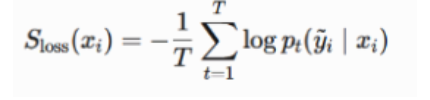

## **Этап 4 Сравнение обнаружения ошибок**

Precision@K, Average Precision и ROC-AUC рассчитываются с использованием маски искусственных ошибок только на этапе оценки. Таблица сортируется по Average Precision

Результаты обнаружения искусственно испорченных меток:


,Метод,Precision@K,Average Precision,ROC-AUC
0,Ablation: without E,0.795000,0.876788,0.956750
1,Cleanlab,0.711667,0.822914,0.916550
2,Small-loss (OOF),0.711667,0.822914,0.916550
3,Dynamics,0.705000,0.818270,0.914382
4,Combined (D+K+E),0.700000,0.773732,0.920815
5,KNN,0.743333,0.771634,0.946106
6,Ablation: without D,0.671667,0.683323,0.897329
7,Ablation: without K,0.626667,0.646875,0.863562
8,Ensemble agreement,0.431667,0.397157,0.782908


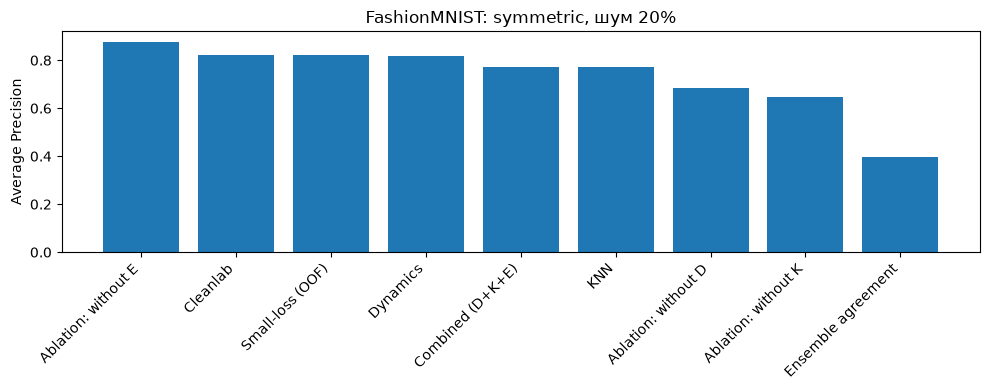

,index,true_label (только оценка),noisy_label,была искусственная ошибка,score
0,822,0,5,1,0.995456
1,1532,6,5,1,0.992586
2,740,6,5,1,0.989529
3,1284,8,3,1,0.988749
4,1137,6,5,1,0.988368
5,1222,1,7,1,0.985863
6,2697,9,3,1,0.985658
7,1886,9,3,1,0.985074
8,1751,1,9,1,0.984286
9,334,9,1,1,0.983210


In [8]:
noise_mask_np = noise_mask.astype(int)  # только для оценки, модель эту маску не получает

results = [evaluate_score(name, score, noise_mask_np) for name, score in score_methods.items()]
results_df = pd.DataFrame(results).sort_values("Average Precision", ascending=False).reset_index(drop=True)
print("Результаты обнаружения искусственно испорченных меток:")
display(results_df)
results_df.to_csv(os.path.join(OUTPUT_DIR, "results_detection_synthetic.csv"), index=False)

plt.figure(figsize=(10, 4))
plt.bar(results_df["Метод"], results_df["Average Precision"])
plt.ylabel("Average Precision")
plt.xticks(rotation=45, ha="right")
plt.title(f"{DATASET_NAME}: {NOISE_TYPE}, шум {NOISE_RATE:.0%}")
plt.tight_layout()
plt.show()

ranked_ids = np.argsort(combined_score)[::-1][:10]
examples = pd.DataFrame({
    "index": ranked_ids,
    "true_label (только оценка)": y_true.numpy()[ranked_ids],
    "noisy_label": y_noisy.numpy()[ranked_ids],
    "была искусственная ошибка": noise_mask_np[ranked_ids],
    "score": combined_score[ranked_ids],
})
display(examples)

# !!!!!TODO: 4, 5 этапы !!!!!!
## еще и при 10%, 40% шума

## Этап 5. Абляционные эксперименты

Сравнивается полная комбинация с вариантами, из которых убран один сигнал. Это позволяет оценить, добавляет ли каждый компонент полезную информацию.

In [9]:
# ЭТАП 5: АБЛЯЦИОННЫЕ ЭКСПЕРИМЕНТЫ
# без D убрана динамика обучения; без K убраны соседи; без E убрано голосование.
combined_ap = results_df.loc[results_df["Метод"] == "Combined (D+K+E)", "Average Precision"].iloc[0]
print("AP полного метода:", round(float(combined_ap), 4))
for method_name in ["Ablation: without D", "Ablation: without K", "Ablation: without E"]:
    value = results_df.loc[results_df["Метод"] == method_name, "Average Precision"].iloc[0]
    print(method_name, "AP =", round(float(value), 4), "разница с полным методом =", round(float(combined_ap - value), 4))

AP полного метода: 0.7737
Ablation: without D AP = 0.6833 разница с полным методом = 0.0904
Ablation: without K AP = 0.6469 разница с полным методом = 0.1269
Ablation: without E AP = 0.8768 разница с полным методом = -0.1031


## Этап 6. Проверка на реальном шуме CIFAR-10N

Этап выключен по умолчанию. Для запуска скачай `CIFAR-10_human.pt` с [официального репозитория CIFAR-N](https://github.com/UCSC-REAL/cifar-10-100n), загрузи его в Colab и установи `RUN_CIFAR10N = True` в ячейке настроек. Протокол использует человеческие метки как шумные, а `clean_label` из бенчмарка — только как опорный вариант для оценки. Оригинальные метки также не следует считать абсолютно безошибочными.

In [10]:
#Настройки для 6 этапа
RUN_CIFAR10N = True
CIFAR10N_LABEL_TYPE = "aggre_label"  # aggre_label, random_label1/2/3, worse_label
CIFAR10N_TRAIN_LIMIT = 3000
CIFAR10N_TEST_LIMIT = 1000
CIFAR10N_FOLDS = 3
CIFAR10N_ENSEMBLE_SIZE = 2
CIFAR10N_EPOCHS = 2


#7 этап работает как на данных 1-5 этапов, так и на данных 6 этапа, эпохи можно увеличить

CLEANING_EPOCHS = 3
CLEANING_USE_CIFAR10N = True  # если true- будут использоваться данные этапа 6


"""
Официальный файл меток: https://github.com/UCSC-REAL/cifar-10-100n
нужен файл: CIFAR-10_human.pt

"""

'\nОфициальный файл меток: https://github.com/UCSC-REAL/cifar-10-100n\nнужен файл: CIFAR-10_human.pt\n\n'

In [11]:
# ЭТАП 6: РЕАЛЬНЫЕ МЕТКИ CIFAR-10N
def load_cifar10n_data(label_type="aggre_label", train_limit=3000, test_limit=1000):
    file_path = "C:/Users/aptem/OneDrive/Desktop/политех/лабы/ВКР/CIFAR-10_human.pt"

    try:
        label_data = torch.load(file_path, map_location="cpu", weights_only=False)
    except TypeError:
        label_data = torch.load(file_path, map_location="cpu")

    if label_type not in label_data:
        raise ValueError(f"В файле нет ключа {label_type}. Доступно: {list(label_data.keys())}")
 
    datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/"
    "resolve/c6e562aecc3a2dd5ee13f9d91630d81219c6a126/"
    "cifar-10-python.tar.gz"
    )

    cifar_train = datasets.CIFAR10(root="C:\\Users\\aptem\\OneDrive\\Desktop\\политех\\лабы\\ВКР\\data",
                                    train=True, download=True)
    cifar_test = datasets.CIFAR10(root="C:\\Users\\aptem\\OneDrive\\Desktop\\политех\\лабы\\ВКР\\data",
                                    train=False, download=True)

    clean_all = torch.as_tensor(label_data["clean_label"], dtype=torch.long)
    noisy_all = torch.as_tensor(label_data[label_type], dtype=torch.long)

    generator = torch.Generator().manual_seed(SEED)
    train_ids = torch.randperm(len(clean_all), generator=generator)[:train_limit]
    test_ids = torch.randperm(len(cifar_test.targets), generator=generator)[:test_limit]

    train_images = torch.as_tensor(cifar_train.data[train_ids.numpy()]).permute(0, 3, 1, 2).float() / 255.0
    test_images = torch.as_tensor(cifar_test.data[test_ids.numpy()]).permute(0, 3, 1, 2).float() / 255.0
    test_labels_all = torch.as_tensor(cifar_test.targets, dtype=torch.long)

    return {
        "X_train": train_images,
        "y_clean": clean_all[train_ids],
        "y_noisy": noisy_all[train_ids],
        "X_test": test_images,
        "y_test": test_labels_all[test_ids],
        "label_type": label_type,
    }


def run_cifar10n_experiment():
    data = load_cifar10n_data(
        label_type=CIFAR10N_LABEL_TYPE,
        train_limit=CIFAR10N_TRAIN_LIMIT,
        test_limit=CIFAR10N_TEST_LIMIT
    )

    real_oof_probs, real_dynamic, real_knn, real_ensemble = get_oof_signals(
        data["X_train"], data["y_noisy"], num_classes=10,
        folds=CIFAR10N_FOLDS, ensemble_size=CIFAR10N_ENSEMBLE_SIZE,
        epochs=CIFAR10N_EPOCHS, seed=SEED + 500
    )

    real_methods, real_combined = make_score_methods(
        data["y_noisy"], real_oof_probs, real_dynamic, real_knn, real_ensemble
    )

    # Reference mask применяется только после ранжирования, для проверки качества.
    real_noise_mask = (data["y_noisy"].numpy() != data["y_clean"].numpy()).astype(int)
    real_results = pd.DataFrame([
        evaluate_score(name, score, real_noise_mask)
        for name, score in real_methods.items()
    ]).sort_values("Average Precision", ascending=False).reset_index(drop=True)

    print("CIFAR-10N label set:", data["label_type"])
    print("Ошибка меток относительно оригинальных CIFAR-10 labels в подвыборке:", f"{real_noise_mask.mean():.2%}")
    display(real_results)

    real_results.to_csv(os.path.join(OUTPUT_DIR, "results_detection_cifar10n.csv"), index=False)
    
    data["oof_probs"] = real_oof_probs
    data["score_methods"] = real_methods
    data["combined_score"] = real_combined
    data["noise_mask"] = real_noise_mask
    data["results_df"] = real_results

    return data


cifar_result = None

if RUN_CIFAR10N:
    cifar_result = run_cifar10n_experiment()


Фолд 1/3
Фолд 2/3
Фолд 3/3
CIFAR-10N label set: aggre_label
Ошибка меток относительно оригинальных CIFAR-10 labels в подвыборке: 8.70%


,Метод,Precision@K,Average Precision,ROC-AUC
0,KNN,0.195402,0.136396,0.641185
1,Ablation: without E,0.141762,0.123865,0.630640
2,Ablation: without D,0.118774,0.114951,0.603631
3,Combined (D+K+E),0.126437,0.112565,0.597168
4,Cleanlab,0.111111,0.104196,0.583932
5,Small-loss (OOF),0.111111,0.104196,0.583932
6,Ablation: without K,0.103448,0.098413,0.545566
7,Dynamics,0.065134,0.093175,0.552350
8,Ensemble agreement,0.107280,0.092475,0.530301


## Этап 7. Проверка пользы очистки

С нуля обучается один классификатор на исходных шумных метках, один после исправления top-K по собственному рейтингу, один после исправления по Cleanlab и один после удаления top-K подозрительных примеров

Этап 7: CIFAR-10N
Доля объектов, выбранных для очистки: 9.0%


,Вариант,Test accuracy,Исправлено/удалено объектов
0,Combined: удаление,0.282,271
1,Исходные шумные метки,0.276,0
2,Combined: исправление,0.255,271
3,Cleanlab: исправление,0.222,271


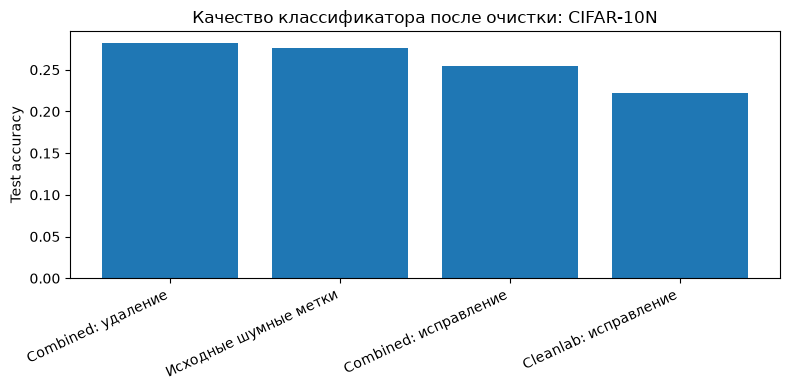

CSV сохранены: /content\results_detection_synthetic.csv и /content\results_cleaning.csv
CSV CIFAR-10N: /content\results_detection_cifar10n.csv


In [12]:
# ЭТАП 7: ПЕРЕОБУЧЕНИЕ ПОСЛЕ ОЧИСТКИ
def train_and_measure(X_train_local, y_train_local, X_test_local, y_test_local,
                      num_classes=10, epochs=3, seed=SEED):
    """Обучает новый классификатор и возвращает точность на чистом test"""
    set_seed(seed)

    model = SimpleCNN(in_channels=X_train_local.shape[1], num_classes=num_classes).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    
    loader = DataLoader(
        TensorDataset(X_train_local, y_train_local),
        batch_size=BATCH_SIZE, shuffle=True
    )

    for _ in range(epochs):
        train_one_epoch(model, loader, optimizer)

    probs, _ = predict(model, X_test_local)
    accuracy = (probs.argmax(axis=1) == y_test_local.cpu().numpy()).mean()
    return float(accuracy)


def repair_labels(y_noisy_local, score, oof_probs_local, fraction):
    y_fixed = y_noisy_local.cpu().numpy().copy()
    count = max(1, int(round(len(y_fixed) * fraction)))

    suspicious_ids = np.argsort(score)[::-1][:count]
    predicted_labels = oof_probs_local.argmax(axis=1)
    
    y_fixed[suspicious_ids] = predicted_labels[suspicious_ids]
    
    return torch.tensor(y_fixed, dtype=torch.long), suspicious_ids


def remove_suspicious(X, y_noisy_local, score, fraction):
    count = max(1, int(round(len(y_noisy_local) * fraction)))

    suspicious_ids = np.argsort(score)[::-1][:count]
  
    keep_mask = np.ones(len(y_noisy_local), dtype=bool)
    keep_mask[suspicious_ids] = False
    
    return X[keep_mask], y_noisy_local[keep_mask], suspicious_ids


def run_cleaning_experiment(X_train_local, y_noisy_local, X_test_local, y_test_local,
                            oof_probs_local, methods_local, top_fraction, epochs=3):

    num_classes = int(max(y_noisy_local.max().item(), y_test_local.max().item()) + 1)
    rows = []

    accuracy = train_and_measure(X_train_local, y_noisy_local, X_test_local, y_test_local,
                                 num_classes, epochs, SEED + 1000)
    rows.append({"Вариант": "Исходные шумные метки", "Test accuracy": accuracy,
                 "Исправлено/удалено объектов": 0})

    # Исправление собственным комбинированным рейтингом
    fixed_y, fixed_ids = repair_labels(
        y_noisy_local, methods_local["Combined (D+K+E)"], oof_probs_local, top_fraction
    )

    accuracy = train_and_measure(X_train_local, fixed_y, X_test_local, y_test_local,
                                 num_classes, epochs, SEED + 1001)
    
    rows.append({"Вариант": "Combined: исправление", "Test accuracy": accuracy,
                 "Исправлено/удалено объектов": len(fixed_ids)})

    # Исправление той же доли объектов по ранжированию Cleanlab
    fixed_cleanlab_y, cleanlab_ids = repair_labels(
        y_noisy_local, methods_local["Cleanlab"], oof_probs_local, top_fraction
    
    )
    accuracy = train_and_measure(X_train_local, fixed_cleanlab_y, X_test_local, y_test_local,
                                 num_classes, epochs, SEED + 1002)
    
    rows.append({"Вариант": "Cleanlab: исправление", "Test accuracy": accuracy,
                 "Исправлено/удалено объектов": len(cleanlab_ids)})

    # Удаление объектов, выбранных собственным рейтингом
    X_kept, y_kept, removed_ids = remove_suspicious(
        X_train_local, y_noisy_local, methods_local["Combined (D+K+E)"], top_fraction
    )
    
    accuracy = train_and_measure(X_kept, y_kept, X_test_local, y_test_local,
                                 num_classes, epochs, SEED + 1003)
    
    rows.append({"Вариант": "Combined: удаление", "Test accuracy": accuracy,
                 "Исправлено/удалено объектов": len(removed_ids)})

    cleaning_results = pd.DataFrame(rows).sort_values("Test accuracy", ascending=False).reset_index(drop=True)
    return cleaning_results


if CLEANING_USE_CIFAR10N:
    if cifar_result is None:
        raise RuntimeError("Сначала установите RUN_CIFAR10N = True и выполните этап 6.")
    
    clean_X_train = cifar_result["X_train"]
    clean_X_test = cifar_result["X_test"]
    
    clean_y_noisy = cifar_result["y_noisy"]
    clean_y_test = cifar_result["y_test"]
    
    clean_oof_probs = cifar_result["oof_probs"]
    clean_methods = cifar_result["score_methods"]

    # Приближённые опубликованные уровни шума CIFAR-10N; это настройка K, не метки объектов

    CIFAR10N_RATES = {
        "aggre_label": 0.0903,
        "random_label1": 0.1723,
        "random_label2": 0.1812,
        "random_label3": 0.1764,
        "worse_label": 0.4021,
    }

    clean_fraction = CIFAR10N_RATES.get(CIFAR10N_LABEL_TYPE, 0.18)
    cleaning_title = "CIFAR-10N"

else:
    clean_X_train = X_train
    clean_X_test = X_test

    clean_y_noisy = y_noisy
    clean_y_test = y_test
    
    clean_oof_probs = oof_probs
    clean_methods = score_methods
    
    clean_fraction = NOISE_RATE
    cleaning_title = DATASET_NAME + " (synthetic noise)"

print("Этап 7:", cleaning_title)
print("Доля объектов, выбранных для очистки:", f"{clean_fraction:.1%}")

cleaning_results = run_cleaning_experiment(
    clean_X_train, clean_y_noisy, clean_X_test, clean_y_test,
    clean_oof_probs, clean_methods, top_fraction=clean_fraction,
    epochs=CLEANING_EPOCHS
)

display(cleaning_results)
cleaning_results.to_csv(os.path.join(OUTPUT_DIR, "results_cleaning.csv"), index=False)

plt.figure(figsize=(8, 4))
plt.bar(cleaning_results["Вариант"], cleaning_results["Test accuracy"])
plt.ylabel("Test accuracy")
plt.xticks(rotation=25, ha="right")
plt.title("Качество классификатора после очистки: " + cleaning_title)
plt.tight_layout()
plt.show()

print("CSV сохранены:", os.path.join(OUTPUT_DIR, "results_detection_synthetic.csv"), "и", os.path.join(OUTPUT_DIR, "results_cleaning.csv"))
if cifar_result is not None:
    print("CSV CIFAR-10N:", os.path.join(OUTPUT_DIR, "results_detection_cifar10n.csv"))

# 8 этап на основе статьи из arxiv
## реализация знаковой энтропии, сравнение с предыдущими методами
### неделя 2, 27.10-3.11

In [13]:
# 8.1
from sklearn.metrics import f1_score

SEI_EPOCHS = 50                                # в статье 150, но для 3000 объектов хватит 30
SEI_LR = 1e-3                                  # скорость обучения 
TAU_GRID = [2.0 / 2**i for i in range(8)]      # 2, 1, 0.5, ..., 0.0156
VAL_NOISE_RATE = 0.20                          # шум на валидационной выборке для подбора tau
VAL_LIMIT = 3000
EVAL_NOISE_TYPES = ["symmetric", "class_dependent", "instance_dependent"]
EVAL_NOISE_RATES = [0.1, 0.2, 0.4]
EVAL_SEEDS = [0, 1, 2]
EPS = 1e-12


@torch.no_grad()#не обучаем модель, а только получаю предсказание
def predict_logits(model, X, batch_size=BATCH_SIZE):
    """Логиты и признаки fc1 для всех объектов"""
    
    model.eval()
    all_logits, all_features = [], []

    for start in range(0, len(X), batch_size):

        ''' выход последнего слоя fc2
            и представление изображения после первого полносвязного слоя fc1 и ReLU'''
        logits, features = model(X[start:start + batch_size].to(DEVICE), return_features=True)
        all_logits.append(logits.cpu().numpy())
        all_features.append(features.cpu().numpy())

    return np.vstack(all_logits), np.vstack(all_features)


#сбор всей информации при обучении
def train_with_trajectory(X, y_obs, num_classes, epochs=SEI_EPOCHS, lr=SEI_LR, seed=SEED):
    set_seed(seed)

    model = SimpleCNN(in_channels=X.shape[1], num_classes=num_classes).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    loader = DataLoader(TensorDataset(X, y_obs), batch_size=BATCH_SIZE, shuffle=True)
    logits_hist, feats_hist = [], []

    for _ in range(epochs):
        train_one_epoch(model, loader, optimizer)
    
        logits, feats = predict_logits(model, X)

        logits_hist.append(logits.astype(np.float32))
        feats_hist.append(feats.astype(np.float32))
    
    return {"logits": np.stack(logits_hist), "features": np.stack(feats_hist)}



'''
теперь есть траектория обучения нейросети: сохранённые логиты 
и признаки каждого изображения после каждой из 50 эпох
значит можно исследовать не только финальное предсказание,
 но и поведение модели на всём протяжении обучения
'''

'\nтеперь есть траектория обучения нейросети: сохранённые логиты \nи признаки каждого изображения после каждой из 50 эпох\nзначит можно исследовать не только финальное предсказание,\n но и поведение модели на всём протяжении обучения\n'

In [14]:
'''траектория -> в числовые метки/оценки'''

# 8.2 ФОРМУЛЫ SEI
def softmax_np(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)


#формулы из статьи: H(pt(x)), мера неопределённости модели
def entropy(P):
    return -(P * np.log(P + EPS)).sum(axis=-1)
#eps для тоо чтобы не было лог(0) 

#возвращает знак SEt(x,y)= +-...
def signed_entropy(P, y):
    H = entropy(P)
    agree = P.argmax(axis=-1) == y[None, :]
    return np.where(agree, H, -H)

# и интеграл SEI = sum SE
def sei_value(P, y):
    return signed_entropy(P, y).sum(axis=0)


def sei_score(P, y):     return -sei_value(P, y)
def ei_score(P, y):      return entropy(P).sum(axis=0)          
def se_last_score(P, y): return -signed_entropy(P, y)[-1]      


def prototype_probs(V, y, num_classes, tau, loo=False):
    E, N, D = V.shape
    onehot = np.eye(num_classes, dtype=np.float32)[y]            
    counts = onehot.sum(axis=0)             

    idx = np.arange(N)
    P = np.empty((E, N, num_classes), dtype=np.float32)

    for e in range(E):
        Ve = V[e]
        T = (onehot.T @ Ve) / np.maximum(counts, 1)[:, None]

        Vn = Ve / (np.linalg.norm(Ve, axis=1, keepdims=True) + EPS)
        Tn = T / (np.linalg.norm(T, axis=1, keepdims=True) + EPS)
        S = Vn @ Tn.T       

        if loo:

            n_own = counts[y][:, None]
            t_loo = (n_own * T[y] - Ve) / np.maximum(n_own - 1, 1)
            t_loo = t_loo / (np.linalg.norm(t_loo, axis=1, keepdims=True) + EPS)
            S[idx, y] = (Vn * t_loo).sum(axis=1)
        
        P[e] = softmax_np(S / tau)
    
    return P


def compute_sei_scores(traj, y, best_tau):
    K = traj["logits"].shape[-1]
    P_soft = softmax_np(traj["logits"])
    
    out = {
        "SEI (softmax логитов)": sei_score(P_soft, y),
        "EI без знака (softmax)": ei_score(P_soft, y),
        "SE@last (softmax)": se_last_score(P_soft, y),
    }

    for (emb, loo), tau in best_tau.items():
        P = prototype_probs(traj[emb], y, K, tau, loo)
        out[f"SEI прототипы [{emb}{', LOO' if loo else ''}]"] = sei_score(P, y)

    return out

AUPRC SEI на softmax логитов (пункт 1) на валидации: 0.5952
Лучшие tau: {('features', False): 2.0, ('features', True): 2.0, ('logits', False): 2.0, ('logits', True): 2.0}


emb      features          logits        
LOO         False   True    False   True 
tau                                      
0.015625   0.4029  0.4017  0.3751  0.3745
0.031250   0.4151  0.4136  0.3945  0.3939
0.062500   0.4430  0.4404  0.4198  0.4194
0.125000   0.4983  0.4958  0.4335  0.4328
0.250000   0.5459  0.5446  0.4791  0.4778
0.500000   0.5658  0.5643  0.5836  0.5819
1.000000   0.5781  0.5764  0.6788  0.6776
2.000000   0.5846  0.5831  0.7209  0.7201

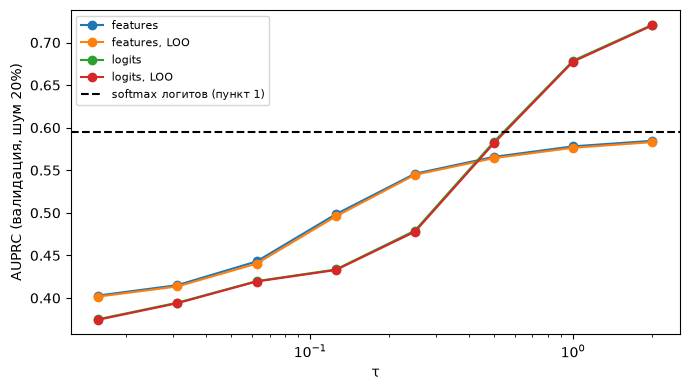

In [15]:
# 8.3 подбор tau на отделной выборке, 
# при этом не пересекается с X_train, 
# AUPRC обнаружения ошибок  
def load_val_subset(dataset_name, train_limit, val_limit):
    DatasetClass = datasets.MNIST if dataset_name.lower() == "mnist" else datasets.FashionMNIST
    data = DatasetClass(root="/content/data", train=True, download=True)

    generator = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(data.targets), generator=generator)   

    ids = perm[train_limit:train_limit + val_limit]         

    X = data.data[ids].float().unsqueeze(1) / 255.0
    y = torch.as_tensor(data.targets, dtype=torch.long)[ids]
    
    return X, y


def tune_tau(X_val, y_val_clean, noise_rate=VAL_NOISE_RATE):

    y_val_noisy, val_mask = make_noisy_labels(X_val, 
                                              y_val_clean,
                                                "symmetric",
                                                  noise_rate,
                                                    seed=SEED + 777)
    val_mask = val_mask.astype(int)
    y_np = y_val_noisy.numpy()
    traj = train_with_trajectory(X_val, y_val_noisy, NUM_CLASSES, SEI_EPOCHS, seed=SEED + 777)

    ref = average_precision_score(val_mask, sei_score(softmax_np(traj["logits"]), y_np))
    rows = []

    for emb in ["features", "logits"]:
        for loo in [False, True]:
            for tau in TAU_GRID:
                P = prototype_probs(traj[emb], y_np, NUM_CLASSES, tau, loo)
                rows.append({"emb": emb, "LOO": loo, "tau": tau,
                             "AUPRC": average_precision_score(val_mask, sei_score(P, y_np))})
                
    df = pd.DataFrame(rows)
    best = df.loc[df.groupby(["emb", "LOO"])["AUPRC"].idxmax()]
    best_tau = {(r.emb, bool(r.LOO)): float(r.tau) for r in best.itertuples()}
    
    return df, best_tau, ref


X_val, y_val_clean = load_val_subset(DATASET_NAME, TRAIN_LIMIT, VAL_LIMIT)
tuning_df, best_tau, ref_auprc = tune_tau(X_val, y_val_clean)

print("AUPRC SEI на softmax логитов (пункт 1) на валидации:", round(ref_auprc, 4))
print("Лучшие tau:", best_tau)
display(tuning_df.pivot_table(index="tau", columns=["emb", "LOO"], values="AUPRC").round(4))

plt.figure(figsize=(7, 4))
for (emb, loo), g in tuning_df.groupby(["emb", "LOO"]):
    plt.plot(g["tau"], g["AUPRC"], marker="o", label=f"{emb}{', LOO' if loo else ''}")
plt.axhline(ref_auprc, color="k", linestyle="--", label="softmax логитов (пункт 1)")
plt.xscale("log"); plt.xlabel("τ"); plt.ylabel("AUPRC (валидация, шум 20%)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()
tuning_df.to_csv(os.path.join(OUTPUT_DIR, "results_tau_tuning.csv"), index=False)

In [ ]:
# 8.4 СРАВНЕНИЕ: SEI, SEI на прототипах и старые методы
# tau из 8.3
def run_one(X_tr, y_tr_clean, noise_type, rate, seed):

    y_noisy_l, mask = make_noisy_labels(X_tr, y_tr_clean, noise_type, rate, seed=SEED + seed)
    mask_i = mask.astype(int)
    y_np = y_noisy_l.numpy()

    traj = train_with_trajectory(X_tr, y_noisy_l, NUM_CLASSES, SEI_EPOCHS, seed=SEED + seed)
    scores = compute_sei_scores(traj, y_np, best_tau)

    oof, dyn, knn, ens = get_oof_signals(X_tr, y_noisy_l, num_classes=NUM_CLASSES, folds=FOLDS,
                                         ensemble_size=ENSEMBLE_SIZE, epochs=EPOCHS, seed=SEED + seed)
    base, _ = make_score_methods(y_noisy_l, oof, dyn, knn, ens)
    scores["Cleanlab"] = base["Cleanlab"]
    scores["Combined (D+K+E)"] = base["Combined (D+K+E)"]

    return [dict(evaluate_score(n, s, mask_i), noise_type=noise_type, rate=rate, seed=seed)
            for n, s in scores.items()]


all_rows = []
for noise_type in EVAL_NOISE_TYPES:
    for rate in EVAL_NOISE_RATES:
        for seed in EVAL_SEEDS:
            print(f"--- {noise_type}, шум {rate:.0%}, seed {seed}")
            all_rows += run_one(X_train, y_true, noise_type, rate, seed)

sei_results = pd.DataFrame(all_rows)
sei_results.to_csv(os.path.join(OUTPUT_DIR, "results_sei_detection.csv"), index=False)

summary = (sei_results.groupby(["noise_type", "rate", "Метод"])["Average Precision"]
           .agg(["mean", "std"]).reset_index())

print("Average Precision, среднее по seed:")
display(summary.pivot_table(index=["noise_type", "rate"], columns="Метод", values="mean").round(3))
print("Среднее по всем настройкам:")
display(sei_results.groupby("Метод")[["Precision@K", "Average Precision", "ROC-AUC"]]
        .mean().sort_values("Average Precision", ascending=False).round(3))

--- symmetric, шум 10%, seed 0
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- symmetric, шум 10%, seed 1
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- symmetric, шум 10%, seed 2
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- symmetric, шум 20%, seed 0
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- symmetric, шум 20%, seed 1
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- symmetric, шум 20%, seed 2
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- symmetric, шум 40%, seed 0
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- symmetric, шум 40%, seed 1
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- symmetric, шум 40%, seed 2
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- class_dependent, шум 10%, seed 0
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- class_dependent, шум 10%, seed 1
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- class_dependent, шум 10%, seed 2
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- class_dependent, шум 20%, seed 0
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- class_dependent, шум 20%, seed 1
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- class_dependent, шум 20%, seed 2
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- class_dependent, шум 40%, seed 0
Фолд 1/3
Фолд 2/3
Фолд 3/3
--- class_dependent, шум 40%, 

Метод                    Cleanlab  Combined (D+K+E)  EI без знака (softmax)  \
noise_type         rate                                                       
class_dependent    0.1      0.742             0.597                   0.109   
                   0.2      0.766             0.648                   0.216   
                   0.4      0.598             0.548                   0.406   
instance_dependent 0.1      0.737             0.641                   0.135   
                   0.2      0.813             0.760                   0.258   
                   0.4      0.884             0.827                   0.491   
symmetric          0.1      0.721             0.641                   0.110   
                   0.2      0.830             0.768                   0.224   
                   0.4      0.875             0.843                   0.428   

Метод                    SE@last (softmax)  SEI (softmax логитов)  \
noise_type         rate                                             
class_dependent    0.1               0.268                  0.366   
                   0.2               0.416                  0.576   
                   0.4               0.525                  0.637   
instance_dependent 0.1               0.308                  0.392   
                   0.2               0.503                  0.620   
                   0.4               0.721                  0.824   
symmetric          0.1               0.277                  0.356   
                   0.2               0.474                  0.583   
                   0.4               0.671                  0.806   

Метод                    SEI прототипы [features, LOO]  \
noise_type         rate                                  
class_dependent    0.1                           0.335   
                   0.2                           0.516   
                   0.4                           0.605   
instance_dependent 0.1                           0.354   
                   0.2                           0.541   
                   0.4                           0.722   
symmetric          0.1                           0.333   
                   0.2                           0.545   
                   0.4                           0.732   

Метод                    SEI прототипы [features]  \
noise_type         rate                             
class_dependent    0.1                      0.338   
                   0.2                      0.517   
                   0.4                      0.607   
instance_dependent 0.1                      0.358   
                   0.2                      0.543   
                   0.4                      0.724   
symmetric          0.1                      0.338   
                   0.2                      0.548   
                   0.4                      0.736   

Метод                    SEI прототипы [logits, LOO]  SEI прототипы [logits]  
noise_type         rate                                                       
class_dependent    0.1                         0.391                   0.393  
                   0.2                         0.561                   0.562  
                   0.4                         0.573                   0.575  
instance_dependent 0.1                         0.460                   0.461  
                   0.2                         0.679                   0.682  
                   0.4                         0.810                   0.811  
symmetric          0.1                         0.507                   0.509  
                   0.2                         0.678                   0.680  
                   0.4                         0.825                   0.827

Среднее по всем настройкам:


,Precision@K,Average Precision,ROC-AUC
Метод,,,
Cleanlab,0.682,0.774,0.881
Combined (D+K+E),0.649,0.697,0.879
SEI прототипы [logits],0.616,0.611,0.900
"SEI прототипы [logits, LOO]",0.614,0.609,0.900
SEI (softmax логитов),0.577,0.573,0.891
SEI прототипы [features],0.524,0.523,0.873
"SEI прототипы [features, LOO]",0.521,0.520,0.872
SE@last (softmax),0.452,0.463,0.832
EI без знака (softmax),0.265,0.264,0.546


In [ ]:
# 8.5 шум CIFAR-10N
# tau взяты с FashionMNIST
if cifar_result is not None:
    d = cifar_result
    y_c = d["y_noisy"].numpy()

    traj_c = train_with_trajectory(d["X_train"], d["y_noisy"], 10, SEI_EPOCHS, seed=SEED + 500)
    
    scores_c = compute_sei_scores(traj_c, y_c, best_tau)
    scores_c["Cleanlab"] = d["score_methods"]["Cleanlab"]
    scores_c["Combined (D+K+E)"] = d["score_methods"]["Combined (D+K+E)"]
    
    cifar_sei_results = (pd.DataFrame([evaluate_score(n, s, d["noise_mask"]) for n, s in scores_c.items()])
                         .sort_values("Average Precision", ascending=False).reset_index(drop=True))
    
    display(cifar_sei_results)
    cifar_sei_results.to_csv(os.path.join(OUTPUT_DIR, "results_sei_cifar10n.csv"), index=False)

,Метод,Precision@K,Average Precision,ROC-AUC
0,SEI (softmax логитов),0.226054,0.173949,0.715956
1,SE@last (softmax),0.168582,0.150646,0.672076
2,SEI прототипы [logits],0.157088,0.149570,0.694403
3,"SEI прототипы [logits, LOO]",0.157088,0.149345,0.694488
4,"SEI прототипы [features, LOO]",0.157088,0.140639,0.677421
5,SEI прототипы [features],0.149425,0.138752,0.675488
6,EI без знака (softmax),0.122605,0.118985,0.617311
7,Combined (D+K+E),0.126437,0.112565,0.597168
8,Cleanlab,0.111111,0.104196,0.583932


# todo: првоерить точность моей обычной cnn(минимум 92%), epochs  увеличить до 100-150, выборку увеличить 
# модели oof обучаются на 2 всего эпохах, а sei на большем количестве. стоит увеличить кол-во эпох.
